In [1]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\kmkb5\Downloads\retail_analytics_submission\retail_analytics_submission
['.venv', 'data', 'docs', 'ganesha1.ps1', 'models', 'notebooks', 'README.md', 'reports', 'requirements.txt', 'result_output.ipynb', 'src']


In [2]:
print(os.path.exists('reports'))

True


In [3]:
print(os.listdir("reports"))

['anomaly_flags.csv', 'data_profile.json', 'department_sales_comovement_proxy_top1000.csv', 'figures', 'findings_and_recommendations.md', 'forecast_predictions.csv', 'model_metrics.json', 'results.ipynb', 'segment_profiles.csv', 'segment_summary.csv']


In [4]:
import json

with open("reports/model_metrics.json", "r") as file:
    metrics = json.load(file)

print(json.dumps(metrics, indent=4))

{
    "forecast": {
        "cutoff": "2012-08-03",
        "test_start": "2012-08-10",
        "test_end": "2012-10-26",
        "n_train": 379398,
        "n_test": 35547,
        "MAE": 1249.882506256871,
        "RMSE": 2640.57950667186,
        "WAPE": 0.08014189348025437
    },
    "silhouette_by_k": {
        "2": 0.30324070507429673,
        "3": 0.36396820423346365,
        "4": 0.3647526180640889,
        "5": 0.369272931636322,
        "6": 0.38378583928972027
    },
    "selected_k": 6,
    "anomaly_candidates": 15793
}


In [5]:
import pandas as pd

anomalies = pd.read_csv(
    "reports/anomaly_flags.csv"
)

display(anomalies.head(10))

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,...,YearEnd,MarkDown1_was_missing,MarkDown2_was_missing,MarkDown3_was_missing,MarkDown4_was_missing,MarkDown5_was_missing,rolling_median_13,rolling_mad_13,robust_z,anomaly_flag
0,1,1,2010-10-15,26978.34,False,A,151315,67.18,2.720,0.00,...,0,1,1,1,1,1,17150.84,1175.27,5.640030,True
1,1,1,2010-10-22,25543.04,False,A,151315,69.86,2.725,0.00,...,0,1,1,1,1,1,17508.41,1194.66,4.536256,True
2,1,1,2010-10-29,38640.93,False,A,151315,69.64,2.716,0.00,...,0,1,1,1,1,1,18122.52,1789.38,7.734231,True
3,1,1,2010-11-05,34238.88,False,A,151315,58.74,2.689,0.00,...,1,1,1,1,1,1,18194.74,1952.96,5.541140,True
4,1,1,2010-12-17,44912.86,False,A,151315,49.84,2.869,0.00,...,1,1,1,1,1,1,22517.56,3025.51,4.992686,True
5,1,1,2011-02-11,37887.17,True,A,151315,36.39,3.022,0.00,...,0,1,1,1,1,1,19549.39,2423.37,5.103910,True
6,1,1,2011-04-22,50510.31,False,A,151315,72.99,3.807,0.00,...,0,1,1,1,1,1,20881.10,2116.37,9.442880,True
7,1,1,2011-04-29,41512.39,False,A,151315,72.03,3.810,0.00,...,0,1,1,1,1,1,21280.40,2116.37,6.447970,True
8,1,1,2011-11-04,39886.06,False,A,151315,54.98,3.332,0.00,...,1,1,1,1,1,1,17859.30,2383.18,6.234043,True
9,1,1,2012-04-06,57592.12,False,A,151315,70.43,3.891,10121.97,...,0,0,1,0,0,0,21140.07,3386.27,7.260665,True


In [6]:
print("Total anomaly candidates:", len(anomalies))

Total anomaly candidates: 15793


In [7]:
print(anomalies.columns.tolist())

['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday', 'Type', 'Size', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday_feature', 'Year', 'Month', 'WeekOfYear', 'Quarter', 'YearEnd', 'MarkDown1_was_missing', 'MarkDown2_was_missing', 'MarkDown3_was_missing', 'MarkDown4_was_missing', 'MarkDown5_was_missing', 'rolling_median_13', 'rolling_mad_13', 'robust_z', 'anomaly_flag']


In [8]:
segments = pd.read_csv(
    "reports/segment_summary.csv"
)

display(segments)

,Segment,store_dept_profiles,mean_sales,sales_volatility,avg_cv,holiday_lift,markdown_mean
0,0,1087,5256.043,1242.848,5.630000e-01,1.069,862.054
1,1,60,22.562,187.672,1.078000e+01,1.262,2480.450
2,2,384,60107.272,12566.119,2.530000e-01,1.090,3244.004
3,3,2,-2.165,214.660,1.186000e+02,194.194,4094.312
4,4,1795,10263.542,3129.656,4.890000e-01,1.111,3434.814
5,5,3,0.000,19.200,1.920031e+07,NaN,233.283


In [9]:
forecast = pd.read_csv(
    "reports/forecast_predictions.csv"
)

display(forecast.head(10))

,Store,Dept,Date,Weekly_Sales,Predicted_Sales,Absolute_Error
0,1,1,2012-08-10,16119.92,16599.598578,479.678578
1,1,1,2012-08-17,17330.70,15858.723651,1471.976349
2,1,1,2012-08-24,16286.40,16864.961307,578.561307
3,1,1,2012-08-31,16680.24,16310.882411,369.357589
4,1,1,2012-09-07,18322.37,17334.231752,988.138248
5,1,1,2012-09-14,19616.22,18082.484656,1533.735344
6,1,1,2012-09-21,19251.50,19162.859295,88.640705
7,1,1,2012-09-28,18947.81,19148.890017,201.080017
8,1,1,2012-10-05,21904.47,20456.860563,1447.609437
9,1,1,2012-10-12,22764.01,22358.403521,405.606479


In [11]:
forecast["Error"] = (
    forecast["Weekly_Sales"] -
    forecast["Predicted_Sales"]
)

display(
    forecast[
        ["Weekly_Sales", "Predicted_Sales", "Error"]
    ].head(10)
)

,Weekly_Sales,Predicted_Sales,Error
0,16119.92,16599.598578,-479.678578
1,17330.70,15858.723651,1471.976349
2,16286.40,16864.961307,-578.561307
3,16680.24,16310.882411,369.357589
4,18322.37,17334.231752,988.138248
5,19616.22,18082.484656,1533.735344
6,19251.50,19162.859295,88.640705
7,18947.81,19148.890017,-201.080017
8,21904.47,20456.860563,1447.609437
9,22764.01,22358.403521,405.606479


In [12]:
print(
    forecast["Error"].abs().mean()
)

1249.882506256871


In [13]:
comovement = pd.read_csv(
    "reports/department_sales_comovement_proxy_top1000.csv"
)

display(comovement.head(10))

,Store,Dept_A,Dept_B,Sales_Correlation
0,28,91,97,0.981836
1,28,92,93,0.976309
2,13,24,33,0.970618
3,36,90,92,0.970270
4,28,90,92,0.969428
5,10,24,33,0.966427
6,4,24,33,0.966224
7,1,24,33,0.965834
8,36,81,92,0.960580
9,36,81,90,0.959798


In [14]:
import pandas as pd
import os

report_files = [
    "anomaly_flags.csv",
    "segment_profiles.csv",
    "segment_summary.csv",
    "forecast_predictions.csv",
    "department_sales_comovement_proxy_top1000.csv"
]

for filename in report_files:

    path = os.path.join("reports", filename)

    if os.path.exists(path):

        data = pd.read_csv(path)

        print("\n" + "=" * 60)
        print("REPORT:", filename)
        print("Shape:", data.shape)
        print("Columns:", data.columns.tolist())

        display(data.head(5))

    else:
        print("Missing report:", filename)


REPORT: anomaly_flags.csv
Shape: (15793, 31)
Columns: ['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday', 'Type', 'Size', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday_feature', 'Year', 'Month', 'WeekOfYear', 'Quarter', 'YearEnd', 'MarkDown1_was_missing', 'MarkDown2_was_missing', 'MarkDown3_was_missing', 'MarkDown4_was_missing', 'MarkDown5_was_missing', 'rolling_median_13', 'rolling_mad_13', 'robust_z', 'anomaly_flag']


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,...,YearEnd,MarkDown1_was_missing,MarkDown2_was_missing,MarkDown3_was_missing,MarkDown4_was_missing,MarkDown5_was_missing,rolling_median_13,rolling_mad_13,robust_z,anomaly_flag
0,1,1,2010-10-15,26978.34,False,A,151315,67.18,2.720,0.0,...,0,1,1,1,1,1,17150.84,1175.27,5.640030,True
1,1,1,2010-10-22,25543.04,False,A,151315,69.86,2.725,0.0,...,0,1,1,1,1,1,17508.41,1194.66,4.536256,True
2,1,1,2010-10-29,38640.93,False,A,151315,69.64,2.716,0.0,...,0,1,1,1,1,1,18122.52,1789.38,7.734231,True
3,1,1,2010-11-05,34238.88,False,A,151315,58.74,2.689,0.0,...,1,1,1,1,1,1,18194.74,1952.96,5.541140,True
4,1,1,2010-12-17,44912.86,False,A,151315,49.84,2.869,0.0,...,1,1,1,1,1,1,22517.56,3025.51,4.992686,True



REPORT: segment_profiles.csv
Shape: (3331, 15)
Columns: ['Store', 'Dept', 'Type', 'Size', 'mean_sales', 'median_sales', 'sales_std', 'sales_cv', 'markdown_mean', 'markdown4_mean', 'negative_sales_rate', 'n_weeks', 'holiday_mean', 'holiday_lift', 'Segment']


,Store,Dept,Type,Size,mean_sales,median_sales,sales_std,sales_cv,markdown_mean,markdown4_mean,negative_sales_rate,n_weeks,holiday_mean,holiday_lift,Segment
0,1,1,A,151315,22513.322937,18535.48,9854.349032,0.437712,2885.518042,1336.016224,0.0,143,25738.594,1.143261,4
1,1,2,A,151315,46102.090420,45561.85,3440.673222,0.074632,2885.518042,1336.016224,0.0,143,44800.334,0.971764,2
2,1,3,A,151315,13150.478042,10366.85,8708.978853,0.662256,2885.518042,1336.016224,0.0,143,11512.537,0.875446,4
3,1,4,A,151315,36964.154476,36579.96,2930.698313,0.079285,2885.518042,1336.016224,0.0,143,39033.911,1.055994,4
4,1,5,A,151315,24257.941119,21183.42,11330.286495,0.467075,2885.518042,1336.016224,0.0,143,37623.458,1.550975,4



REPORT: segment_summary.csv
Shape: (6, 7)
Columns: ['Segment', 'store_dept_profiles', 'mean_sales', 'sales_volatility', 'avg_cv', 'holiday_lift', 'markdown_mean']


,Segment,store_dept_profiles,mean_sales,sales_volatility,avg_cv,holiday_lift,markdown_mean
0,0,1087,5256.043,1242.848,0.563,1.069,862.054
1,1,60,22.562,187.672,10.780,1.262,2480.450
2,2,384,60107.272,12566.119,0.253,1.090,3244.004
3,3,2,-2.165,214.660,118.600,194.194,4094.312
4,4,1795,10263.542,3129.656,0.489,1.111,3434.814



REPORT: forecast_predictions.csv
Shape: (35547, 6)
Columns: ['Store', 'Dept', 'Date', 'Weekly_Sales', 'Predicted_Sales', 'Absolute_Error']


,Store,Dept,Date,Weekly_Sales,Predicted_Sales,Absolute_Error
0,1,1,2012-08-10,16119.92,16599.598578,479.678578
1,1,1,2012-08-17,17330.70,15858.723651,1471.976349
2,1,1,2012-08-24,16286.40,16864.961307,578.561307
3,1,1,2012-08-31,16680.24,16310.882411,369.357589
4,1,1,2012-09-07,18322.37,17334.231752,988.138248



REPORT: department_sales_comovement_proxy_top1000.csv
Shape: (1000, 4)
Columns: ['Store', 'Dept_A', 'Dept_B', 'Sales_Correlation']


,Store,Dept_A,Dept_B,Sales_Correlation
0,28,91,97,0.981836
1,28,92,93,0.976309
2,13,24,33,0.970618
3,36,90,92,0.970270
4,28,90,92,0.969428


In [15]:
import pandas as pd

forecast = pd.read_csv(
    "reports/forecast_predictions.csv"
)

print(forecast.shape)

print(forecast.columns.tolist())

display(forecast.head(10))

(35547, 6)
['Store', 'Dept', 'Date', 'Weekly_Sales', 'Predicted_Sales', 'Absolute_Error']


,Store,Dept,Date,Weekly_Sales,Predicted_Sales,Absolute_Error
0,1,1,2012-08-10,16119.92,16599.598578,479.678578
1,1,1,2012-08-17,17330.70,15858.723651,1471.976349
2,1,1,2012-08-24,16286.40,16864.961307,578.561307
3,1,1,2012-08-31,16680.24,16310.882411,369.357589
4,1,1,2012-09-07,18322.37,17334.231752,988.138248
5,1,1,2012-09-14,19616.22,18082.484656,1533.735344
6,1,1,2012-09-21,19251.50,19162.859295,88.640705
7,1,1,2012-09-28,18947.81,19148.890017,201.080017
8,1,1,2012-10-05,21904.47,20456.860563,1447.609437
9,1,1,2012-10-12,22764.01,22358.403521,405.606479


In [16]:
print(forecast.dtypes)

Store                int64
Dept                 int64
Date                   str
Weekly_Sales       float64
Predicted_Sales    float64
Absolute_Error     float64
dtype: object


In [17]:
print(forecast["Date"].head(10))

0    2012-08-10
1    2012-08-17
2    2012-08-24
3    2012-08-31
4    2012-09-07
5    2012-09-14
6    2012-09-21
7    2012-09-28
8    2012-10-05
9    2012-10-12
Name: Date, dtype: str


In [18]:
print("Total records:", len(forecast))

print(
    "Unique dates:",
    forecast["Date"].nunique()
)

Total records: 35547
Unique dates: 12


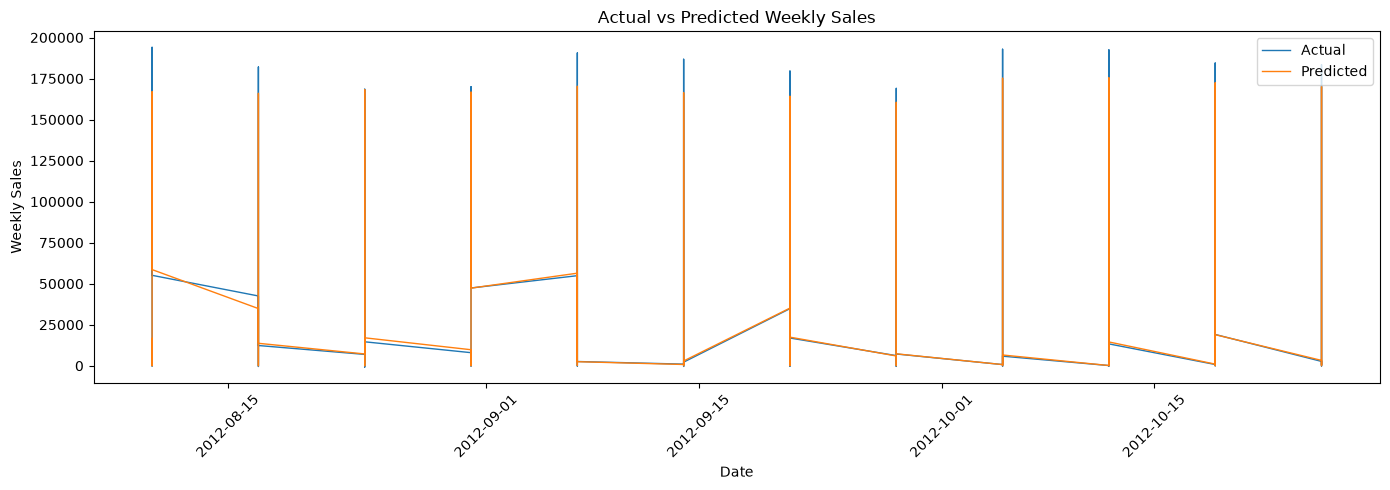

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

forecast["Date"] = pd.to_datetime(
    forecast["Date"]
)

forecast = forecast.sort_values("Date")

plt.figure(figsize=(14, 5))

plt.plot(
    forecast["Date"],
    forecast["Weekly_Sales"],
    label="Actual",
    linewidth=1
)

plt.plot(
    forecast["Date"],
    forecast["Predicted_Sales"],
    label="Predicted",
    linewidth=1
)

plt.title("Actual vs Predicted Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
# Aggregate actual and predicted sales by date

weekly_forecast = (
    forecast.groupby("Date")
    [["Weekly_Sales", "Predicted_Sales"]]
    .sum()
    .reset_index()
)

weekly_forecast = weekly_forecast.sort_values("Date")

display(weekly_forecast.head(10))

,Date,Weekly_Sales,Predicted_Sales
0,2012-08-10,47403421.16,4.702091e+07
1,2012-08-17,47354481.05,4.687112e+07
2,2012-08-24,47447279.72,4.765145e+07
3,2012-08-31,47159634.96,4.789000e+07
4,2012-09-07,48330040.90,4.818734e+07
5,2012-09-14,44226007.10,4.649429e+07
6,2012-09-21,44354523.20,4.376714e+07
7,2012-09-28,43734899.40,4.358558e+07
8,2012-10-05,47566629.05,4.649878e+07
9,2012-10-12,46128484.37,4.658439e+07


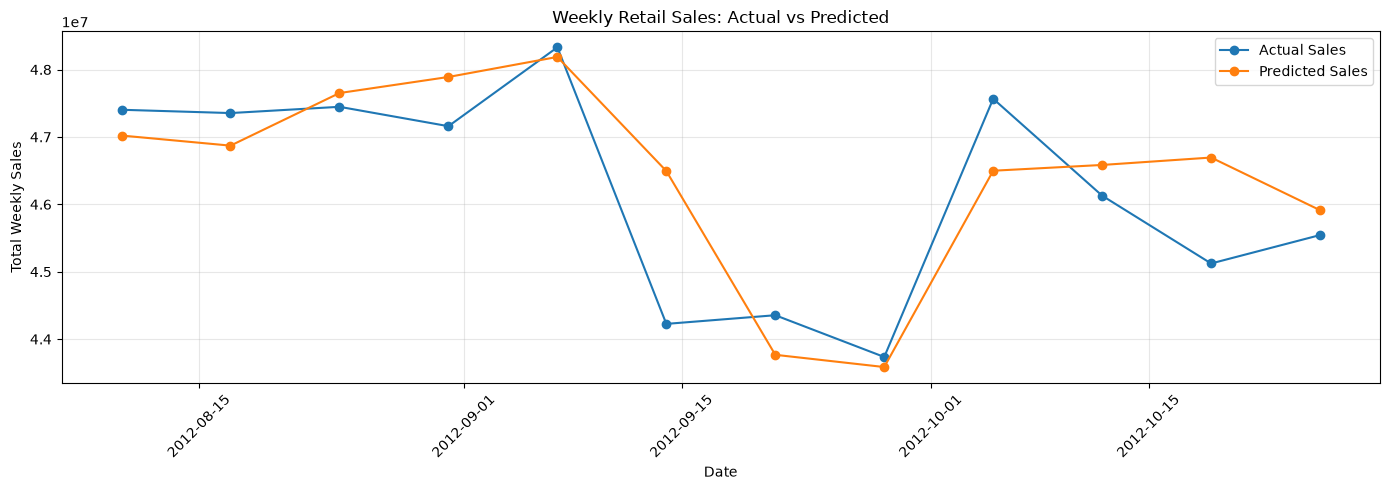

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    weekly_forecast["Date"],
    weekly_forecast["Weekly_Sales"],
    label="Actual Sales",
    marker="o"
)

plt.plot(
    weekly_forecast["Date"],
    weekly_forecast["Predicted_Sales"],
    label="Predicted Sales",
    marker="o"
)

plt.title("Weekly Retail Sales: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()